# APS360 Final Project — QFrCoLA: Source-Disjoint Evaluation & CamemBERT

**Study:** Quebec French linguistic acceptability classification (0 = unacceptable; 1 = acceptable).  
**Objective:** Compare a pretrained French sequence classifier (E5) with the archived E1–E4 experiments, using the **same source-disjoint split**.

### How to run
1. **Part A0** checks the Hugging Face environment. If it repairs the environment, it deliberately stops: **restart the Python kernel / Local Runtime, then Run All again**. The installer does not run again if versions and imports are healthy.
2. Run Parts **A–G** for data preparation, E5 training, **validation-only** model selection, and error analysis. The notebook reloads an existing E5 checkpoint instead of automatically retraining it.
3. Optionally enable additional training seeds in **Part E**; each seed is saved separately.
4. **Only after the model and threshold are finalized on validation**, change `RUN_FINAL_TEST = True` in Part H and run that cell. This evaluates the QFrCoLA test data **once** and caches the result.
5. Part I evaluates a genuinely independent, manually labeled CSV *only if provided*. No labels or metrics are fabricated.

### Experimental safeguards
- Part B/C are preserved from the original Progress notebook; the selected split must reproduce **seed 372**, **17,580 / 3,734 / 3,839** samples. Any mismatch fails fast.
- **Do not re-train E1–E4.** Their prior results are explicitly marked as historical comparisons.
- The QFrCoLA test split was already inspected during the Progress Report; it is **not a pristine never-before-seen test set** for the overall project. A separate external holdout remains desirable.
- Training requires a CUDA-capable GPU by default, to avoid accidentally running lengthy fine-tuning on CPU.
- Outputs in this supplied notebook were intentionally cleared. It has **not** been executed against your local runtime or GPU.

Sources: [QFrCoLA dataset](https://huggingface.co/datasets/graalul/qfrcola) · [CamemBERT model](https://huggingface.co/almanach/camembert-base) · [Progress notebook](https://github.com/Electronic-Dolphin/APS360-Project/blob/main/APS360_QFrCoLA_Progress.ipynb).

## Part A0 — One-time dependency verification / repair

**This replaces both the old `%pip -q install -U datasets ...` from Part A and all installer/debug cells from the previous Part D.** They must **not** be run again.

This cell checks the installed versions **and verifies the imports in a fresh subprocess**. It only uninstalls/reinstalls the Hugging Face trio if a problem is detected. Once repaired, restart the **local** Python kernel before continuing. The `aps360` Conda environment is used via `sys.executable`; there is no change to other Conda environments.

Package versions are fixed to avoid the observed `HfMount`, `HF_HUB_ENABLE_HF_TRANSFER`, and dataset/hub dependency conflicts. The original `pip -U datasets` command must stay removed.

In [1]:
# A0 — Safe, idempotent environment check and one-time repair
import sys
import subprocess
import importlib.metadata as metadata

REQUIRED_VERSIONS = {
    "datasets": "3.6.0",
    "transformers": "4.57.3",
    "huggingface-hub": "0.36.2",
}

def installed_version(package):
    try:
        return metadata.version(package)
    except metadata.PackageNotFoundError:
        return None

current_versions = {p: installed_version(p) for p in REQUIRED_VERSIONS}
smoke_test = r"""
import datasets, transformers, huggingface_hub
from datasets import load_dataset, Dataset
from transformers import AutoTokenizer, AutoModelForSequenceClassification, DataCollatorWithPadding
from huggingface_hub import snapshot_download
from huggingface_hub import constants
assert hasattr(constants, 'HF_HUB_ENABLE_HF_TRANSFER')
assert datasets.__version__ == '3.6.0'
assert transformers.__version__ == '4.57.3'
assert huggingface_hub.__version__ == '0.36.2'
"""
probe = subprocess.run(
    [sys.executable, "-c", smoke_test],
    capture_output=True, text=True, check=False,
)
healthy = (all(current_versions[p] == v for p, v in REQUIRED_VERSIONS.items())
           and probe.returncode == 0)
print("Python:", sys.executable)
print("Hugging Face versions:", current_versions)
if healthy:
    print("A0 OK — Hugging Face dependencies are consistent. No installation needed.")
else:
    print("Environment needs repair. Subprocess diagnostic:")
    print((probe.stderr or "Version mismatch")[-1800:])
    print("Removing only the three conflicting Hugging Face packages...")
    subprocess.run([
        sys.executable, "-m", "pip", "uninstall", "-y",
        "datasets", "transformers", "huggingface-hub"
    ], check=True)
    # pip sometimes leaves orphaned files from a newer Hub release; these
    # caused the observed HfMount / constants errors. Clean ONLY package code
    # in the active Python environment; never remove user caches or datasets.
    import sysconfig
    import shutil
    from pathlib import Path
    package_root = Path(sysconfig.get_paths()["purelib"]).resolve()
    env_root = Path(sys.prefix).resolve()
    assert package_root.is_relative_to(env_root), (package_root, env_root)
    for name in ("huggingface_hub", "datasets", "transformers"):
        leftover = package_root / name
        if leftover.is_dir():
            print("Cleaning stale package files:", leftover)
            shutil.rmtree(leftover)
    subprocess.run([
        sys.executable, "-m", "pip", "install", "--no-cache-dir",
        "datasets==3.6.0", "transformers==4.57.3",
        "huggingface-hub==0.36.2", "sentencepiece>=0.2,<0.3",
        "safetensors>=0.4.5", "scikit-learn", "pandas",
        "matplotlib", "tqdm"
    ], check=True)
    raise RuntimeError(
        "Dependency repair installed. RESTART the Local Runtime / Python kernel "
        "now, then run the notebook again from Part A0. "
        "Do not run the old 'pip -U datasets' cell."
    )

Python: C:\Users\<local-user>\miniconda3\envs\aps360\python.exe
Hugging Face versions: {'datasets': '3.6.0', 'transformers': '4.57.3', 'huggingface-hub': '0.36.2'}
A0 OK — Hugging Face dependencies are consistent. No installation needed.


## Part A — Download and inspect QFrCoLA

Source preparation from the archived Progress Report. It remains unchanged to maintain comparability of the split. The earlier unpinned installation cell has been removed.

In [2]:
import os, re, random, unicodedata, copy, json, sys, platform
from collections import Counter
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from datasets import load_dataset
from sklearn.model_selection import GroupShuffleSplit
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score, f1_score, matthews_corrcoef,
                             confusion_matrix, classification_report, ConfusionMatrixDisplay)

SEED = 360
random.seed(SEED)
np.random.seed(SEED)
OUT = Path('qfrcola_results')
OUT.mkdir(exist_ok=True)
print('Python:', sys.version.split()[0], '| pandas:', pd.__version__)
print('Output directory:', OUT.resolve())

C:\Users\<local-user>\miniconda3\envs\aps360\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Python: 3.11.18 | pandas: 3.1.1
Output directory: C:\Users\<local-user>\qfrcola_results


In [3]:
dataset = load_dataset('graalul/qfrcola')
print('Official splits:', {k: len(v) for k, v in dataset.items()})
df_raw = pd.concat(
    [dataset[k].to_pandas().assign(original_split=k) for k in dataset],
    ignore_index=True
)
required = {'sentence','label','source','category'}
assert required.issubset(df_raw.columns), f'Missing columns: {required - set(df_raw.columns)}'
print('Raw rows:', len(df_raw))
print('Columns:', df_raw.columns.tolist())
display(df_raw[['sentence','label','category','source']].head(5))
print('Missing values:')
print(df_raw[['sentence','label','category','source']].isna().sum().to_string())
print('Raw label counts:', df_raw['label'].value_counts(dropna=False).to_dict())
print('Raw categories:')
display(df_raw['category'].value_counts(dropna=False).to_frame('count'))

Official splits: {'train': 15846, 'validation': 1761, 'test': 7546}
Raw rows: 25153
Columns: ['label', 'sentence', 'source', 'category', 'original_split']


,sentence,label,category,source
0,Je participerai au congrès à moins que des obl...,1,syntax,https://vitrinelinguistique.oqlf.gouv.qc.ca/22...
1,Les météorologues ne s’expliquent pas la vague...,1,semantic,https://vitrinelinguistique.oqlf.gouv.qc.ca/25...
2,"La journée était calme : point de vent, poing ...",0,morphology,https://vitrinelinguistique.oqlf.gouv.qc.ca/22...
3,Le juge s’est objecté à la remise en liberté d...,0,morphology,https://vitrinelinguistique.oqlf.gouv.qc.ca/22...
4,L’adjectif s’accorde avec le nom ou le pronom ...,1,syntax,https://vitrinelinguistique.oqlf.gouv.qc.ca/24...


Missing values:
sentence    0
label       0
category    0
source      0
Raw label counts: {1: 17479, 0: 7674}
Raw categories:


,count
category,
morphology,10642
semantic,5442
syntax,5152
anglicism,3917


## Part B — Clean, deduplicate and connect shared sources

Keep the **accents, case and apostrophe spellings** intact in the stored sentences (e.g. `l’`, `qu’`). We normalize Unicode (NFC) and repeated whitespace only; dropping accents or punctuation could change acceptability labels.

For repeated texts, first link all their source URLs into one connected group; then remove duplicate text examples. If an identical normalized sentence has both labels, exclude all occurrences and report the count rather than arbitrarily assigning a label.

In [4]:
def normalize_sentence(s):
    s = unicodedata.normalize('NFC', str(s))
    return re.sub(r'\s+', ' ', s).strip()

df = df_raw.copy()
# Drop malformed rows before string conversion (NaN must not become the literal 'nan').
missing = df[['sentence','source','label']].isna().any(axis=1)
df = df.loc[~missing].copy()
df['sentence'] = df['sentence'].map(normalize_sentence)
df['source'] = df['source'].astype(str).str.strip()
df['category'] = df['category'].fillna('unknown').astype(str).str.strip().str.lower()
df['label'] = pd.to_numeric(df['label'], errors='coerce')
df = df.loc[(df['sentence'] != '') & (df['source'] != '') & df['label'].isin([0,1])].copy()
df['label'] = df['label'].astype(int)

class DSU:
    def __init__(self, items):
        self.parent = {x:x for x in items}
    def find(self, x):
        while self.parent[x] != x:
            self.parent[x] = self.parent[self.parent[x]]
            x = self.parent[x]
        return x
    def union(self, a, b):
        ra, rb = self.find(a), self.find(b)
        if ra != rb:
            self.parent[rb] = ra

dsu = DSU(df['source'].unique())
# A sentence appearing on two different source pages links those pages.
for _, urls in df.groupby('sentence', sort=False)['source']:
    unique_urls = urls.unique()
    for url in unique_urls[1:]:
        dsu.union(unique_urls[0], url)

conflicting_sentences = df.groupby('sentence')['label'].nunique()
conflicting_sentences = set(conflicting_sentences[conflicting_sentences > 1].index)
conflicting_rows = int(df['sentence'].isin(conflicting_sentences).sum())
n_before = len(df)
df = df.loc[~df['sentence'].isin(conflicting_sentences)].drop_duplicates('sentence', keep='first').copy()
df['source_group'] = df['source'].map(dsu.find)

audit = {
    'raw_rows': len(df_raw), 'malformed_or_missing_removed': len(df_raw) - n_before,
    'conflicting_sentences': len(conflicting_sentences),
    'conflicting_rows_removed': conflicting_rows,
    'exact_duplicate_rows_removed': int(n_before - conflicting_rows - len(df)),
    'cleaned_rows': len(df), 'source_urls_remaining': df['source'].nunique(),
    'connected_source_groups': df['source_group'].nunique()
}
print('Cleaning audit:')
print(json.dumps(audit, indent=2, ensure_ascii=False))
assert df['sentence'].is_unique
assert not df[['sentence','source']].isna().any().any()
assert set(df['label'].unique()) <= {0,1}
assert df['source_group'].nunique() >= 3, 'Too few disjoint source groups to split into 3 partitions'
if conflicting_sentences:
    print('Review conflicting texts:')
    display(pd.DataFrame({'sentence': sorted(conflicting_sentences)}).head(8))
display(df[['sentence','label','category','source','source_group']].head(4))

Cleaning audit:
{
  "raw_rows": 25153,
  "malformed_or_missing_removed": 0,
  "conflicting_sentences": 0,
  "conflicting_rows_removed": 0,
  "exact_duplicate_rows_removed": 0,
  "cleaned_rows": 25153,
  "source_urls_remaining": 2798,
  "connected_source_groups": 2798
}


,sentence,label,category,source,source_group
0,Je participerai au congrès à moins que des obl...,1,syntax,https://vitrinelinguistique.oqlf.gouv.qc.ca/22...,https://vitrinelinguistique.oqlf.gouv.qc.ca/22...
1,Les météorologues ne s’expliquent pas la vague...,1,semantic,https://vitrinelinguistique.oqlf.gouv.qc.ca/25...,https://vitrinelinguistique.oqlf.gouv.qc.ca/25...
2,"La journée était calme : point de vent, poing ...",0,morphology,https://vitrinelinguistique.oqlf.gouv.qc.ca/22...,https://vitrinelinguistique.oqlf.gouv.qc.ca/22...
3,Le juge s’est objecté à la remise en liberté d...,0,morphology,https://vitrinelinguistique.oqlf.gouv.qc.ca/22...,https://vitrinelinguistique.oqlf.gouv.qc.ca/22...


## Part C — 70/15/15 split grouped by source page

The default QFrCoLA splits may not follow the proposed grouping scheme, so this experiment **pools all 25,153 in-domain examples before splitting**. The `source_group` key is the connected component of all URLs sharing a normalized sentence. We select a deterministic random split close to target sizes and class balance, **without using model predictions**.

In [5]:
def score_candidate(frame, inds):
    target = [0.70, 0.15, 0.15]
    n = len(frame)
    pos_share = frame['label'].mean()
    score = 0.0
    for ids, t in zip(inds, target):
        sub = frame.iloc[ids]
        if sub['label'].nunique() < 2 or len(sub) == 0:
            return float('inf')
        score += 3.0 * abs(len(sub) / n - t)
        score += abs(sub['label'].mean() - pos_share)
        # Keep anglicism representation in all partitions where feasible.
        if 'anglicism' in set(frame['category']) and not (sub['category'] == 'anglicism').any():
            score += 3
    return score

best = None
for trial in range(50):
    randseed = SEED + trial
    splitter = GroupShuffleSplit(n_splits=1, test_size=0.15, random_state=randseed)
    trainval_i, test_i = next(splitter.split(df, groups=df['source_group']))
    trainval = df.iloc[trainval_i]
    splitter2 = GroupShuffleSplit(n_splits=1, test_size=(0.15 / 0.85), random_state=randseed + 10000)
    train_local, val_local = next(splitter2.split(trainval, groups=trainval['source_group']))
    train_i, val_i = trainval_i[train_local], trainval_i[val_local]
    ids = (train_i, val_i, test_i)
    score = score_candidate(df, ids)
    if best is None or score < best[0]:
        best = (score, randseed, ids)

assert np.isfinite(best[0]), 'Could not obtain a split with both labels and anglicisms in all groups'
_, chosen_seed, (train_i, val_i, test_i) = best
split_frames = [df.iloc[idx].copy() for idx in (train_i, val_i, test_i)]
for s, name in zip(split_frames, ['train','validation','test']):
    s['split'] = name
train_df, val_df, test_df = split_frames
full = pd.concat(split_frames, ignore_index=True)
assert sum(map(len, split_frames)) == len(df)
assert len(set(train_df.source_group) & set(val_df.source_group)) == 0
assert len(set(train_df.source_group) & set(test_df.source_group)) == 0
assert len(set(val_df.source_group) & set(test_df.source_group)) == 0
assert len(set(train_df.source) & set(test_df.source)) == 0
assert len(set(train_df.sentence) & set(test_df.sentence)) == 0
print(f'Selected deterministic split seed: {chosen_seed}; score: {best[0]:.4f}')
print('No shared source groups, URLs or normalized sentences across partitions.')
print('Split sizes:', {k:len(d) for k,d in zip(['train','validation','test'],split_frames)})

Selected deterministic split seed: 372; score: 0.0246
No shared source groups, URLs or normalized sentences across partitions.
Split sizes: {'train': 17580, 'validation': 3734, 'test': 3839}


Summary:


,rows,source_pages,source_groups,acceptable_rate,percent
split,,,,,
train,17580,1958,1958,0.695,69.892
validation,3734,420,420,0.690,14.845
test,3839,420,420,0.698,15.263


Class counts by split:


label,unacceptable (0),acceptable (1)
split,,
train,5358,12222
validation,1158,2576
test,1158,2681


Category counts by split:


split,train,validation,test,all
category,,,,
morphology,7308,1718,1616,10642
semantic,3811,695,936,5442
syntax,3630,777,745,5152
anglicism,2831,544,542,3917


Anglicism label counts:


label,0,1
split,,
train,1169,1662
validation,235,309
test,231,311


Example of cleaned training data:


,sentence,label,category,source
14961,La sculpture est le médium favori de Karen.,0,anglicism,https://vitrinelinguistique.oqlf.gouv.qc.ca/23...
2673,Ton frère prévoit changer son baladeur MP3 pou...,1,syntax,https://vitrinelinguistique.oqlf.gouv.qc.ca/24...
2322,Les personnes qui font des exercices à haute i...,0,anglicism,https://vitrinelinguistique.oqlf.gouv.qc.ca/21...
5423,Cette robe griffée vaut 600 dollars.,1,semantic,https://vitrinelinguistique.oqlf.gouv.qc.ca/23...
13964,La journaliste avait appris cette nouvelle de ...,1,morphology,https://vitrinelinguistique.oqlf.gouv.qc.ca/22...


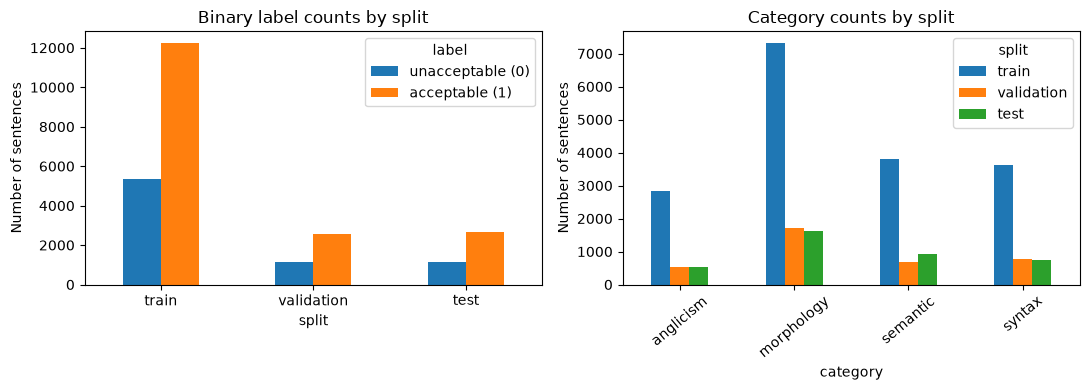

In [6]:
summary = full.groupby('split').agg(
    rows=('sentence','size'), source_pages=('source','nunique'),
    source_groups=('source_group','nunique'), acceptable_rate=('label','mean')
).reindex(['train','validation','test'])
summary['percent'] = 100 * summary['rows'] / len(full)
print('Summary:')
display(summary.round(3))

label_counts = pd.crosstab(full['split'], full['label']).reindex(['train','validation','test'], fill_value=0)
label_counts = label_counts.reindex(columns=[0,1],fill_value=0).rename(columns={0:'unacceptable (0)',1:'acceptable (1)'})
print('Class counts by split:')
display(label_counts)

category_counts = pd.crosstab(full['category'],full['split']).reindex(columns=['train','validation','test'], fill_value=0)
category_counts['all'] = category_counts.sum(axis=1)
print('Category counts by split:')
display(category_counts.sort_values('all',ascending=False))

anglicisms = full.loc[full['category'] == 'anglicism']
print('Anglicism label counts:')
display(pd.crosstab(anglicisms['split'], anglicisms['label']).reindex(['train','validation','test'], fill_value=0))
print('Example of cleaned training data:')
display(train_df[['sentence','label','category','source']].sample(min(5,len(train_df)),random_state=SEED))

summary.to_csv(OUT/'split_summary.csv')
label_counts.to_csv(OUT/'label_counts.csv')
category_counts.to_csv(OUT/'category_counts.csv')
for name, ds in zip(['train','validation','test'],split_frames):
    ds[['sentence','label','source','category','source_group']].to_csv(OUT/f'{name}.csv',index=False)
with open(OUT/'cleaning_audit.json','w',encoding='utf-8') as f:
    json.dump({**audit, 'split_seed':chosen_seed},f,indent=2,ensure_ascii=False)

fig, axs = plt.subplots(1,2,figsize=(11,4))
label_counts.plot(kind='bar', ax=axs[0], title='Binary label counts by split', rot=0)
category_counts.drop(columns='all').plot(kind='bar', ax=axs[1], title='Category counts by split', rot=40)
for ax in axs: ax.set_ylabel('Number of sentences')
fig.tight_layout()
fig.savefig(OUT/'split_distributions.png',dpi=180,bbox_inches='tight')
plt.show()

In [7]:
# Verify the original source-disjoint split

print("Selected split seed:", chosen_seed)
print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

assert chosen_seed == 372
assert len(train_df) == 17580
assert len(val_df) == 3734
assert len(test_df) == 3839

# Check for source leakage
assert set(train_df["source_group"]).isdisjoint(
    set(val_df["source_group"])
)
assert set(train_df["source_group"]).isdisjoint(
    set(test_df["source_group"])
)
assert set(val_df["source_group"]).isdisjoint(
    set(test_df["source_group"])
)

print("Data restored successfully!")
print("No source overlap between partitions.")

Selected split seed: 372
Train: 17580
Validation: 3734
Test: 3839
Data restored successfully!
No source overlap between partitions.


### Shared evaluation utilities

Metrics are evaluated on **validation** during development. Test metrics are computed only in Part H after the final selection is frozen. Explicit `labels=[0, 1]` avoids confusion-matrix shape changes for a single-class subgroup.

In [8]:
# Shared classification metrics; no model training here
from sklearn.metrics import (
    accuracy_score, f1_score, matthews_corrcoef,
    confusion_matrix, classification_report
)

def evaluate(y_true, pred):
    y_true = np.asarray(y_true, dtype=int)
    pred = np.asarray(pred, dtype=int)
    assert len(y_true) == len(pred) and len(y_true) > 0
    return {
        "accuracy": float(accuracy_score(y_true, pred)),
        "macro_f1": float(f1_score(y_true, pred, average="macro",
                                   labels=[0, 1], zero_division=0)),
        "mcc": float(matthews_corrcoef(y_true, pred)),
        "f1_unacceptable": float(f1_score(y_true, pred, pos_label=0,
                                          zero_division=0)),
        "f1_acceptable": float(f1_score(y_true, pred, pos_label=1,
                                        zero_division=0)),
    }

print("Evaluation functions ready.")

Evaluation functions ready.


## Part D — CamemBERT tokenizer & datasets

CamemBERT uses a pretrained SentencePiece/subword tokenizer. **Do not reuse the old word vocabulary, char CNN, or 20-word sequence length.** We use the same QFrCoLA train and validation rows but generate new `input_ids` and `attention_mask`.

The tokenizer is downloaded into the Hugging Face cache, then loaded from a **local snapshot directory** to avoid the observed `additional_chat_templates` 404 request. The first download requires Internet; the Windows symlink warning is harmless (the cache may use more disk space).

In [12]:
# D1 — Tokenizer setup (no pip commands here)
import torch
import transformers
import datasets
import huggingface_hub
from datasets import Dataset as HFDataset
from torch.utils.data import DataLoader
from huggingface_hub import snapshot_download
from transformers import AutoTokenizer, DataCollatorWithPadding
from pathlib import Path

MODEL_NAME = "almanach/camembert-base"
FINAL_OUT = Path("qfrcola_final_results")
FINAL_OUT.mkdir(parents=True, exist_ok=True)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Packages:", {
    "torch": torch.__version__, "transformers": transformers.__version__,
    "datasets": datasets.__version__, "hub": huggingface_hub.__version__,
})
print("Device:", DEVICE)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("WARNING: CUDA unavailable. Fine-tuning is blocked by default in Part E.")

# Download only tokenizer files; never request the absent chat-template directory.
TOKENIZER_SNAPSHOT = snapshot_download(
    repo_id=MODEL_NAME,
    allow_patterns=[
        "config.json", "tokenizer.json", "tokenizer_config.json",
        "sentencepiece.bpe.model", "special_tokens_map.json",
        "added_tokens.json"
    ],
)
tokenizer = AutoTokenizer.from_pretrained(
    TOKENIZER_SNAPSHOT, use_fast=True, local_files_only=True
)
print("Tokenizer snapshot:", TOKENIZER_SNAPSHOT)
print("Tokenizer vocabulary:", tokenizer.vocab_size)
print("Special tokens:", tokenizer.special_tokens_map)
print("Sample tokens:", tokenizer.tokenize("J'aime l'école au Québec."))
print("Tokenizer loaded successfully.")

Packages: {'torch': '2.11.0+cu128', 'transformers': '4.57.3', 'datasets': '3.6.0', 'hub': '0.36.2'}
Device: cuda
GPU: NVIDIA GeForce RTX 3060


Fetching 4 files: 100%|██████████| 4/4 [00:00<00:00, 1000.01it/s]

Tokenizer snapshot: C:\Users\<local-user>\.cache\huggingface\hub\models--almanach--camembert-base\snapshots\a75967561c78f2aa81cc41045378d3b4ee25af9e
Tokenizer vocabulary: 32005
Special tokens: {'bos_token': '<s>', 'eos_token': '</s>', 'unk_token': '<unk>', 'sep_token': '</s>', 'pad_token': '<pad>', 'cls_token': '<s>', 'mask_token': '<mask>', 'additional_special_tokens': ['<s>NOTUSED', '</s>NOTUSED', '<unk>NOTUSED']}
Sample tokens: ['▁J', "'", 'aime', '▁l', "'", 'école', '▁au', '▁Québec', '.']
Tokenizer loaded successfully.


In [13]:
# D2 — Inspect French tokenization and choose a maximum sequence length
examples = [
    "J'aime l’école et qu’il soit prêt.",
    "L’assurance-emploi est importante au Québec.",
    "Je n’en ai pas besoin !",
    "La sculpture est le médium favori de Karen."
]
for sentence in examples:
    token_ids = tokenizer(sentence, add_special_tokens=True)["input_ids"]
    print("\nSentence:", sentence)
    print("Subwords:", tokenizer.convert_ids_to_tokens(token_ids))
    print("Count:", len(token_ids))

# Investigate lengths from the training split only; do not look at test lengths.
train_lengths = np.asarray([
    len(ids) for ids in tokenizer(
        train_df["sentence"].astype(str).tolist(),
        add_special_tokens=True, truncation=False, padding=False
    )["input_ids"]
], dtype=int)

MAX_SUBWORDS = 64  # Includes <s> and </s>; raise to 96/128 if truncation is large
print("\nTraining token length percentiles p50, p95, p99:",
      np.percentile(train_lengths, [50, 95, 99]))
truncation_rate = float(np.mean(train_lengths > MAX_SUBWORDS))
print(f"Training examples truncated at {MAX_SUBWORDS}: {truncation_rate:.2%}")
if truncation_rate > 0.05:
    print("WARNING: >5% of training sentences truncate. Consider MAX_SUBWORDS=96 "
          "before training, and document the choice.")


Sentence: J'aime l’école et qu’il soit prêt.
Subwords: ['<s>', '▁J', "'", 'aime', '▁l', '’', 'école', '▁et', '▁qu', '’', 'il', '▁soit', '▁prêt', '.', '</s>']
Count: 15

Sentence: L’assurance-emploi est importante au Québec.
Subwords: ['<s>', '▁L', '’', 'assurance', '-', 'emploi', '▁est', '▁importante', '▁au', '▁Québec', '.', '</s>']
Count: 12

Sentence: Je n’en ai pas besoin !
Subwords: ['<s>', '▁Je', '▁n', '’', 'en', '▁ai', '▁pas', '▁besoin', '▁!', '</s>']
Count: 10

Sentence: La sculpture est le médium favori de Karen.
Subwords: ['<s>', '▁La', '▁sculpture', '▁est', '▁le', '▁médium', '▁favori', '▁de', '▁Kar', 'en', '.', '</s>']
Count: 12

Training token length percentiles p50, p95, p99: [16. 26. 33.]
Training examples truncated at 64: 0.01%


In [14]:
# D3 — Create tokenized train/validation datasets and dynamic-padding loaders
from functools import partial

def frame_to_hf(frame):
    return HFDataset.from_dict({
        "sentence": frame["sentence"].astype(str).tolist(),
        "labels": frame["label"].astype(int).tolist()
    })

def tokenize_batch(batch):
    return tokenizer(batch["sentence"], truncation=True,
                     max_length=MAX_SUBWORDS, padding=False)

def tokenize_frame(frame):
    return frame_to_hf(frame).map(
        tokenize_batch, batched=True, remove_columns=["sentence"],
        desc="CamemBERT subword tokenization"
    )

train_tokenized = tokenize_frame(train_df)
val_tokenized = tokenize_frame(val_df)
collator = DataCollatorWithPadding(tokenizer=tokenizer, return_tensors="pt")

# Windows Local Runtime: num_workers=0 avoids DataLoader process spawning issues.
def make_loader(tokenized_dataset, batch_size, shuffle=False, seed=360):
    generator = torch.Generator().manual_seed(int(seed))
    return DataLoader(
        tokenized_dataset, batch_size=batch_size, shuffle=shuffle,
        collate_fn=collator, num_workers=0,
        pin_memory=(DEVICE.type == "cuda"), generator=generator
    )

print("Tokenized split sizes:", len(train_tokenized), len(val_tokenized))
assert (len(train_tokenized), len(val_tokenized)) == (17580, 3734)
example_batch = next(iter(make_loader(train_tokenized, batch_size=8)))
for field, value in example_batch.items():
    print(field, tuple(value.shape), value.dtype)
assert set(example_batch) >= {"input_ids", "attention_mask", "labels"}
assert example_batch["input_ids"].shape[1] <= MAX_SUBWORDS
assert set(example_batch["labels"].tolist()) <= {0, 1}
# Fingerprint actual split contents so cached checkpoints cannot be reused
# silently after a data/splitting change.
import hashlib

def split_fingerprint(*named_frames):
    h = hashlib.sha256()
    for name, frame in named_frames:
        h.update(name.encode("utf-8"))
        h.update(frame[["sentence", "label", "source", "source_group"]].to_csv(
            index=False
        ).encode("utf-8"))
    return h.hexdigest()

DATA_FINGERPRINT = split_fingerprint(
    ("train", train_df), ("validation", val_df), ("test", test_df)
)
print("Dataset split SHA-256:", DATA_FINGERPRINT)
print("Part D completed successfully.")

CamemBERT subword tokenization: 100%|██████████| 3734/3734 [00:00<00:00, 46364.97 examples/s]


Tokenized split sizes: 17580 3734
labels (8,) torch.int64
input_ids (8, 24) torch.int64
attention_mask (8, 24) torch.int64
Dataset split SHA-256: 20d55676cac1ed725df969075c558ecdbcb352503e52d98fd7a681f347ca6f25
Part D completed successfully.


## Part E — E5 CamemBERT fine-tuning

**Model:** `AutoModelForSequenceClassification` initialized from pretrained `almanach/camembert-base`; a newly initialized binary classification head is expected and trained with the encoder.

**Main E5 protocol:** standard (unweighted) cross-entropy, `AdamW`, learning rate `2e-5`, max 4 epochs, validation Macro-F1 for checkpoint selection, early stopping after 2 epochs without improvement, batch size 8 with 2-step gradient accumulation (effective 16), max 64 subwords. Automatic mixed precision is used on CUDA.

- **Training and model selection use only train + validation.** No test labels are accessed here.
- Models and metrics are saved under `qfrcola_final_results/e5_seed_*/`. If a complete checkpoint already exists, the notebook **loads it** instead of training it again.
- Change `RUN_EXTRA_SEEDS` to `True` only if compute permits. All seeds use the same **data split**, but different training randomness.
- Avoid uploading large pretrained model weights or temporary caches to GitHub; the Notebook and CSV/JSON results are sufficient for source-code review.

In [15]:
# E1 — Hyperparameters and pretrained model weights (from local snapshot)
from transformers import AutoModelForSequenceClassification, get_linear_schedule_with_warmup
from tqdm.auto import tqdm
import math
import time

TRAIN_BATCH_SIZE = 8
EVAL_BATCH_SIZE = 16
GRAD_ACCUM_STEPS = 2
EPOCHS = 4
EARLY_STOP_PATIENCE = 2
LEARNING_RATE = 2e-5
WEIGHT_DECAY = 0.01
WARMUP_RATIO = 0.10
GRAD_CLIP_NORM = 1.0
REQUIRE_CUDA = True  # Avoid accidentally running long fine-tuning on CPU
RUN_EXTRA_SEEDS = True  # Set True only if you want two additional independent trainings
TRAINING_SEEDS = [360, 361, 362] if RUN_EXTRA_SEEDS else [360]
FORCE_RETRAIN = False  # Existing best checkpoints are preserved by default

# Download ONLY safetensors + config: no redundant pytorch_model.bin or TensorFlow weights.
MODEL_SNAPSHOT = snapshot_download(
    repo_id=MODEL_NAME,
    allow_patterns=["config.json", "model.safetensors"],
)
assert (Path(MODEL_SNAPSHOT) / "model.safetensors").exists(), (
    "model.safetensors was not found in the snapshot; verify model files or network."
)
print("Model weights ready in Hugging Face cache:", MODEL_SNAPSHOT)
print("Training seeds:", TRAINING_SEEDS)
print("GPU required to train:", REQUIRE_CUDA)
print("Checkpoint root:", FINAL_OUT.resolve())

Fetching 2 files: 100%|██████████| 2/2 [00:00<00:00, 153.16it/s]

Model weights ready in Hugging Face cache: C:\Users\<local-user>\.cache\huggingface\hub\models--almanach--camembert-base\snapshots\a75967561c78f2aa81cc41045378d3b4ee25af9e
Training seeds: [360, 361, 362]
GPU required to train: True
Checkpoint root: C:\Users\<local-user>\qfrcola_final_results


In [16]:
# E2 — Training and validation helpers
from torch.optim import AdamW
from sklearn.metrics import confusion_matrix

def seed_everything(seed):
    random.seed(int(seed))
    np.random.seed(int(seed))
    torch.manual_seed(int(seed))
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(int(seed))
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True

def model_from_pretrained():
    # Sequence-classification head is randomly initialized; this warning is expected.
    return AutoModelForSequenceClassification.from_pretrained(
        MODEL_SNAPSHOT, num_labels=2, local_files_only=True,
        use_safetensors=True
    )

def _to_device(batch):
    return {k: v.to(DEVICE, non_blocking=(DEVICE.type == "cuda"))
            for k, v in batch.items()}

@torch.no_grad()
def predict_loader(model, loader, desc="Evaluate"):
    model.eval()
    probabilities, labels = [], []
    loss_total, n_total = 0.0, 0
    for batch in tqdm(loader, desc=desc, leave=False):
        batch = _to_device(batch)
        outputs = model(**batch)
        bs = int(batch["labels"].size(0))
        loss_total += float(outputs.loss.item()) * bs
        n_total += bs
        probabilities.append(torch.softmax(outputs.logits, dim=-1)[:, 1].cpu().numpy())
        labels.append(batch["labels"].cpu().numpy())
    y = np.concatenate(labels)
    prob1 = np.concatenate(probabilities)
    assert len(y) == n_total
    return y, prob1, (loss_total / n_total)

def summarize_probs(y_true, prob1, threshold=0.5):
    preds = (np.asarray(prob1) >= threshold).astype(int)
    return evaluate(y_true, preds)

def load_checkpoint(folder):
    folder = Path(folder)
    assert (folder / "config.json").exists(), f"Missing trained checkpoint at {folder}"
    model = AutoModelForSequenceClassification.from_pretrained(
        str(folder), local_files_only=True, use_safetensors=True
    )
    return model.to(DEVICE)

print("Training utilities ready.")

Training utilities ready.


In [17]:
# Restore the previously selected CamemBERT model
# No retraining required.

import json
from pathlib import Path

FINAL_OUT = Path("qfrcola_final_results")

# Read the saved validation-based selection
with open(FINAL_OUT / "selection.json", encoding="utf-8") as f:
    selection = json.load(f)

BEST_SEED = int(selection["seed"])
SELECTED_THRESHOLD = float(selection["threshold"])

BEST_CHECKPOINT = (
    FINAL_OUT / f"e5_seed_{BEST_SEED}" / "best_model"
)

# Check that saved weights exist
assert (BEST_CHECKPOINT / "model.safetensors").exists(), \
    "Saved model weights not found!"

# Restore the fine-tuned model
best_model = load_checkpoint(BEST_CHECKPOINT)

print("Model restored successfully!")
print("Seed:", BEST_SEED)
print("Threshold:", SELECTED_THRESHOLD)
print("Checkpoint:", BEST_CHECKPOINT)

Model restored successfully!
Seed: 360
Threshold: 0.8
Checkpoint: qfrcola_final_results\e5_seed_360\best_model


In [ ]:
# E3 — Train one seed or resume from previously saved best checkpoint

def train_one_seed(seed):
    run_dir = FINAL_OUT / f"e5_seed_{seed}"
    run_dir.mkdir(parents=True, exist_ok=True)
    best_dir = run_dir / "best_model"
    metadata_path = run_dir / "run_summary.json"
    history_path = run_dir / "training_history.csv"

    if (not FORCE_RETRAIN and metadata_path.exists()
            and (best_dir / "config.json").exists()
            and (best_dir / "model.safetensors").exists()):
        print(f"Seed {seed}: existing best checkpoint found; skipping training.")
        with open(metadata_path, "r", encoding="utf-8") as f:
            previous = json.load(f)
        # Reusing a checkpoint with different data or hyperparameters would
        # produce misleading comparisons, so fail explicitly.
        compatible = (
            previous.get("data_fingerprint") == DATA_FINGERPRINT
            and previous.get("model") == MODEL_NAME
            and previous.get("max_subwords") == MAX_SUBWORDS
            and previous.get("learning_rate") == LEARNING_RATE
            and previous.get("train_batch_size") == TRAIN_BATCH_SIZE
            and previous.get("grad_accum_steps") == GRAD_ACCUM_STEPS
        )
        if not compatible:
            raise RuntimeError(
                f"Seed {seed} checkpoint was made with different data or settings. "
                "Archive/move its directory, or deliberately set FORCE_RETRAIN=True "
                "after reviewing the differences."
            )
        return previous

    if REQUIRE_CUDA and DEVICE.type != "cuda":
        raise RuntimeError(
            "CUDA is not available in your Local Runtime. Enable a compatible GPU "
            "and PyTorch CUDA build before training; otherwise set REQUIRE_CUDA=False "
            "only if you intentionally want CPU training."
        )

    seed_everything(seed)
    train_loader = make_loader(train_tokenized, TRAIN_BATCH_SIZE,
                               shuffle=True, seed=seed)
    val_loader = make_loader(val_tokenized, EVAL_BATCH_SIZE)
    model = model_from_pretrained().to(DEVICE)
    optimizer = AdamW(model.parameters(), lr=LEARNING_RATE,
                      weight_decay=WEIGHT_DECAY)
    updates_per_epoch = math.ceil(len(train_loader) / GRAD_ACCUM_STEPS)
    num_steps = updates_per_epoch * EPOCHS
    scheduler = get_linear_schedule_with_warmup(
        optimizer,
        num_warmup_steps=max(1, int(num_steps * WARMUP_RATIO)),
        num_training_steps=num_steps,
    )
    amp_enabled = DEVICE.type == "cuda"
    bf16_enabled = amp_enabled and torch.cuda.is_bf16_supported()
    amp_dtype = torch.bfloat16 if bf16_enabled else torch.float16
    scaler = torch.amp.GradScaler("cuda", enabled=(amp_enabled and not bf16_enabled))

    best_f1, best_mcc, best_val_loss, best_epoch = -1.0, -2.0, float("inf"), None
    no_improve = 0
    history = []
    for epoch in range(1, EPOCHS + 1):
        model.train()
        epoch_loss_total, n_total = 0.0, 0
        optimizer.zero_grad(set_to_none=True)
        start = time.time()

        for idx, batch in enumerate(tqdm(train_loader,
                                          desc=f"Seed {seed} · epoch {epoch}/{EPOCHS}",
                                          leave=False)):
            batch = _to_device(batch)
            n = int(batch["labels"].size(0))
            # Correct normalization even in a short final gradient-accumulation group.
            group_start = (idx // GRAD_ACCUM_STEPS) * GRAD_ACCUM_STEPS
            group_size = min(GRAD_ACCUM_STEPS, len(train_loader) - group_start)
            with torch.autocast(device_type=DEVICE.type, dtype=amp_dtype,
                                enabled=amp_enabled):
                outputs = model(**batch)
                loss_raw = outputs.loss
                loss = loss_raw / group_size
            scaler.scale(loss).backward()
            epoch_loss_total += float(loss_raw.detach().item()) * n
            n_total += n

            if ((idx + 1) % GRAD_ACCUM_STEPS == 0 or
                    (idx + 1) == len(train_loader)):
                scaler.unscale_(optimizer)
                torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP_NORM)
                scaler.step(optimizer)
                scaler.update()
                scheduler.step()
                optimizer.zero_grad(set_to_none=True)

        y_val, prob_val, val_loss = predict_loader(
            model, val_loader, desc=f"Validation seed {seed} epoch {epoch}"
        )
        scores = summarize_probs(y_val, prob_val, threshold=0.5)
        row = {
            "seed": seed, "epoch": epoch,
            "train_loss": epoch_loss_total / n_total,
            "val_loss": val_loss,
            **scores, "seconds": float(time.time() - start)
        }
        history.append(row)
        print(f"seed={seed} epoch={epoch}: train={row['train_loss']:.4f} "
              f"val={val_loss:.4f} macro-F1={scores['macro_f1']:.4f} "
              f"MCC={scores['mcc']:.4f}")
        pd.DataFrame(history).to_csv(history_path, index=False)

        improved = (
            scores["macro_f1"] > best_f1 + 1e-8 or
            (abs(scores["macro_f1"] - best_f1) <= 1e-8
             and (scores["mcc"] > best_mcc + 1e-8 or
                  (abs(scores["mcc"] - best_mcc) <= 1e-8
                   and val_loss < best_val_loss)))
        )
        if improved:
            best_f1, best_mcc = scores["macro_f1"], scores["mcc"]
            best_val_loss, best_epoch = val_loss, epoch
            no_improve = 0
            model.save_pretrained(str(best_dir), safe_serialization=True)
            tokenizer.save_pretrained(str(best_dir))
            print("  Best validation checkpoint saved:", best_dir)
        else:
            no_improve += 1
            if no_improve >= EARLY_STOP_PATIENCE:
                print("  Early stopping: no improvement for", no_improve, "epochs")
                break

    best_row = next(r for r in history if r["epoch"] == best_epoch)
    summary = {
        "seed": seed, "model": MODEL_NAME, "best_epoch": int(best_epoch),
        "data_fingerprint": DATA_FINGERPRINT,
        "best_val_loss": float(best_val_loss),
        "val_accuracy": float(best_row["accuracy"]),
        "val_macro_f1": float(best_f1), "val_mcc": float(best_mcc),
        "val_f1_unacceptable": float(best_row["f1_unacceptable"]),
        "val_f1_acceptable": float(best_row["f1_acceptable"]),
        "train_batch_size": TRAIN_BATCH_SIZE,
        "eval_batch_size": EVAL_BATCH_SIZE,
        "grad_accum_steps": GRAD_ACCUM_STEPS,
        "max_subwords": MAX_SUBWORDS,
        "max_epochs": EPOCHS,
        "learning_rate": LEARNING_RATE, "weight_decay": WEIGHT_DECAY,
        "validation_checkpoint_objective": "macro_f1_then_mcc_then_loss",
        "checkpoint": str(best_dir),
        "device": str(DEVICE),
    }
    with open(metadata_path, "w", encoding="utf-8") as f:
        json.dump(summary, f, indent=2, ensure_ascii=False)
    del model, optimizer, scheduler
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()
    return summary

print("E5 seed training function ready.")

E5 seed training function ready.


In [ ]:
# E4 — Execute main E5 run; optional multiple seeds
run_summaries = []
for current_seed in TRAINING_SEEDS:
    run_summaries.append(train_one_seed(current_seed))

runs_df = pd.DataFrame(run_summaries).sort_values(
    ["val_macro_f1", "val_mcc"], ascending=False
).reset_index(drop=True)
display(runs_df[["seed", "best_epoch", "val_macro_f1", "val_mcc",
                 "val_f1_unacceptable", "val_f1_acceptable", "best_val_loss"]])
runs_df.to_csv(FINAL_OUT / "e5_validation_runs.csv", index=False)

# Choose the best run using validation only.
BEST_SEED = int(runs_df.iloc[0]["seed"])
BEST_CHECKPOINT = FINAL_OUT / f"e5_seed_{BEST_SEED}" / "best_model"
print("Selected E5 seed (validation only):", BEST_SEED)
print("Best checkpoint:", BEST_CHECKPOINT)

Seed 360: existing best checkpoint found; skipping training.


Some weights of CamembertForSequenceClassification were not initialized from the model checkpoint at C:\Users\<local-user>\.cache\huggingface\hub\models--almanach--camembert-base\snapshots\a75967561c78f2aa81cc41045378d3b4ee25af9e and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


seed=361 epoch=1: train=0.5172 val=0.5072 macro-F1=0.7181 MCC=0.5085
  Best validation checkpoint saved: qfrcola_final_results\e5_seed_361\best_model


seed=361 epoch=2: train=0.3775 val=0.5357 macro-F1=0.7294 MCC=0.5214
  Best validation checkpoint saved: qfrcola_final_results\e5_seed_361\best_model


seed=361 epoch=3: train=0.3022 val=0.6320 macro-F1=0.7159 MCC=0.5179


seed=361 epoch=4: train=0.2564 val=0.6275 macro-F1=0.7324 MCC=0.5257


... (4 outputs left out)

seed=362 epoch=3: train=0.3123 val=0.5467 macro-F1=0.7405 MCC=0.5280
  Best validation checkpoint saved: qfrcola_final_results\e5_seed_362\best_model


seed=362 epoch=4: train=0.2570 val=0.6293 macro-F1=0.7378 MCC=0.5262


,seed,best_epoch,val_macro_f1,val_mcc,val_f1_unacceptable,val_f1_acceptable,best_val_loss
0,360,3,0.740610,0.531507,0.606330,0.874890,0.568546
1,362,3,0.740517,0.528010,0.607163,0.873872,0.546678
2,361,4,0.732441,0.525735,0.590780,0.874103,0.627504


Selected E5 seed (validation only): 360
Best checkpoint: qfrcola_final_results\e5_seed_360\best_model


## Part F — Validation-only selection & comparison

Choose the decision threshold using **validation predictions** from the selected checkpoint. Save this value before looking at test predictions. Report both the default 0.50 threshold and tuned threshold; this is a post-training calibration choice, not a separately trained model.

Historical E1–E4 numbers below come from the Progress Report and were not re-executed here. Comparisons should acknowledge possible differences in experiment randomness and model selection procedures.

E5 validation @ threshold=0.50:


,accuracy,macro_f1,mcc,f1_unacceptable,f1_acceptable
0,0.8101,0.7406,0.5315,0.6063,0.8749


Selected validation threshold: 0.8
E5 validation scores at selected threshold:


,accuracy,macro_f1,mcc,f1_unacceptable,f1_acceptable
0,0.812,0.7507,0.5352,0.627,0.8743


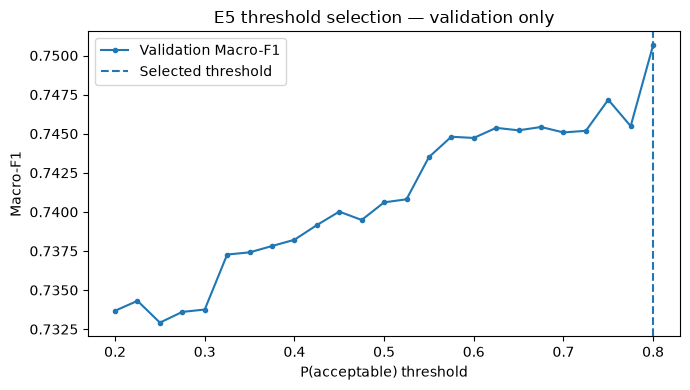

In [ ]:
# F1 — Load selected trained E5 model and obtain validation probabilities
best_model = load_checkpoint(BEST_CHECKPOINT)
val_loader = make_loader(val_tokenized, EVAL_BATCH_SIZE, shuffle=False)
y_val, val_prob1, val_loss = predict_loader(
    best_model, val_loader, desc="Selected E5 / validation"
)
assert np.array_equal(y_val, val_df["label"].to_numpy(dtype=int))
np.savez_compressed(FINAL_OUT / "selected_validation_predictions.npz",
                    label=y_val, prob1=val_prob1)

fixed_scores = summarize_probs(y_val, val_prob1, threshold=0.5)
print("E5 validation @ threshold=0.50:")
display(pd.DataFrame([fixed_scores]).round(4))

# Only validation probabilities are used to select a threshold.
threshold_rows = []
for threshold in np.round(np.arange(0.20, 0.801, 0.025), 3):
    result = summarize_probs(y_val, val_prob1, float(threshold))
    threshold_rows.append({"threshold": float(threshold), **result})
threshold_df = pd.DataFrame(threshold_rows)
threshold_df = threshold_df.sort_values(
    ["macro_f1", "mcc", "threshold"],
    ascending=[False, False, True]
).reset_index(drop=True)
SELECTED_THRESHOLD = float(threshold_df.iloc[0]["threshold"])
SELECTED_VAL_SCORES = summarize_probs(y_val, val_prob1, SELECTED_THRESHOLD)

print("Selected validation threshold:", SELECTED_THRESHOLD)
print("E5 validation scores at selected threshold:")
display(pd.DataFrame([SELECTED_VAL_SCORES]).round(4))
threshold_df.to_csv(FINAL_OUT / "validation_threshold_search.csv", index=False)
with open(FINAL_OUT / "selection.json", "w", encoding="utf-8") as f:
    json.dump({
        "model": MODEL_NAME, "seed": BEST_SEED,
        "checkpoint": str(BEST_CHECKPOINT),
        "selection": "highest validation macro-F1 then MCC",
        "threshold": SELECTED_THRESHOLD,
        "validation_at_0_5": fixed_scores,
        "validation_at_selected_threshold": SELECTED_VAL_SCORES,
    }, f, indent=2, ensure_ascii=False)

fig, ax = plt.subplots(figsize=(7, 4))
ordered_thresholds = threshold_df.sort_values("threshold")
ax.plot(ordered_thresholds["threshold"], ordered_thresholds["macro_f1"],
        marker=".", label="Validation Macro-F1")
ax.axvline(SELECTED_THRESHOLD, linestyle="--", label="Selected threshold")
ax.set(xlabel="P(acceptable) threshold", ylabel="Macro-F1",
       title="E5 threshold selection — validation only")
ax.legend()
fig.tight_layout()
fig.savefig(FINAL_OUT / "validation_threshold_macro_f1.png", dpi=180)
plt.show()

,experiment,macro_f1,mcc
0,E1 TF-IDF + LR (historical),0.5114,0.0242
1,"E2 Word BiLSTM (initial, historical)",0.4901,-0.0198
2,E3 CharCNN + BiLSTM (historical),0.4889,-0.0217
3,"E4 weighted BiLSTM (controlled, historical)",0.4852,-0.0292
4,"E4 unweighted BiLSTM (controlled, historical)",0.4081,-0.0110
5,"E4 32-D weighted (controlled, historical)",0.4848,-0.0304
6,E5 CamemBERT seed 360 @0.50 (new),0.7406,0.5315
7,E5 CamemBERT seed 360 tuned (new),0.7507,0.5352


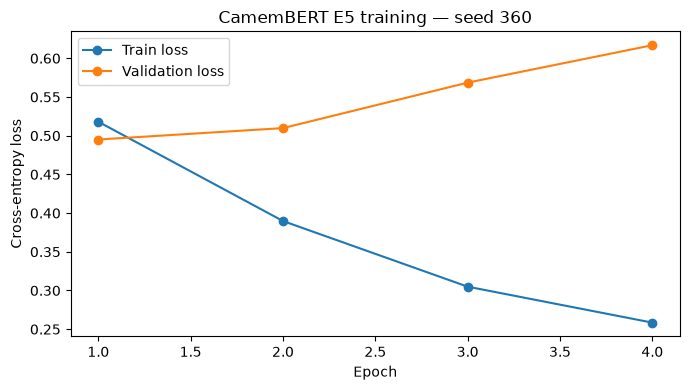

In [ ]:
# F2 — Validation comparison against historical E1–E4 results
# These reference values were reported in the Progress Report, not rerun here.
historical_val = [
    {"experiment": "E1 TF-IDF + LR (historical)", "macro_f1": 0.5114, "mcc": 0.0242},
    {"experiment": "E2 Word BiLSTM (initial, historical)", "macro_f1": 0.4901, "mcc": -0.0198},
    {"experiment": "E3 CharCNN + BiLSTM (historical)", "macro_f1": 0.4889, "mcc": -0.0217},
    {"experiment": "E4 weighted BiLSTM (controlled, historical)", "macro_f1": 0.4852, "mcc": -0.0292},
    {"experiment": "E4 unweighted BiLSTM (controlled, historical)", "macro_f1": 0.4081, "mcc": -0.0110},
    {"experiment": "E4 32-D weighted (controlled, historical)", "macro_f1": 0.4848, "mcc": -0.0304},
    {"experiment": f"E5 CamemBERT seed {BEST_SEED} @0.50 (new)",
     "macro_f1": fixed_scores["macro_f1"], "mcc": fixed_scores["mcc"]},
    {"experiment": f"E5 CamemBERT seed {BEST_SEED} tuned (new)",
     "macro_f1": SELECTED_VAL_SCORES["macro_f1"],
     "mcc": SELECTED_VAL_SCORES["mcc"]},
]
comparison_val = pd.DataFrame(historical_val)
comparison_val.to_csv(FINAL_OUT / "validation_model_comparison.csv", index=False)
display(comparison_val.round(4))

# Optional multi-seed summary; validation metrics only.
if len(runs_df) > 1:
    summary = runs_df[["val_macro_f1", "val_mcc"]].agg(["mean", "std"])
    print("E5 multi-seed validation (checkpoint threshold 0.5):")
    display(summary.round(4))

# Training curves from the SELECTED seed
history_csv = FINAL_OUT / f"e5_seed_{BEST_SEED}" / "training_history.csv"
if history_csv.exists():
    history = pd.read_csv(history_csv)
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.plot(history["epoch"], history["train_loss"], marker="o", label="Train loss")
    ax.plot(history["epoch"], history["val_loss"], marker="o", label="Validation loss")
    ax.set(xlabel="Epoch", ylabel="Cross-entropy loss",
           title=f"CamemBERT E5 training — seed {BEST_SEED}")
    ax.legend()
    fig.tight_layout()
    fig.savefig(FINAL_OUT / "e5_training_curves.png", dpi=180)
    plt.show()

## Part G — Validation error analysis (including anglicisms)

The following analyses use **validation data only**. They include per-category Macro-F1, class recall, confusion matrix, and confidently wrong examples for qualitative review. The text examples illustrate model behavior, not a proof of why an error occurred.

,category,samples,label0_count,label1_count,label0_recall,label1_recall,accuracy,macro_f1,mcc,f1_unacceptable,f1_acceptable
1,morphology,1718,556,1162,0.5953,0.9234,0.8172,0.7753,0.5647,0.6783,0.8724
3,syntax,777,197,580,0.4162,0.9655,0.8263,0.7205,0.4918,0.5485,0.8924
2,semantic,695,170,525,0.5176,0.9619,0.8532,0.7707,0.5690,0.6331,0.9083
0,anglicism,544,235,309,0.3787,0.9838,0.7224,0.6710,0.4750,0.5410,0.8011


E5 validation confusion matrix (true label rows; predicted columns):
[[ 590  568]
 [ 134 2442]]


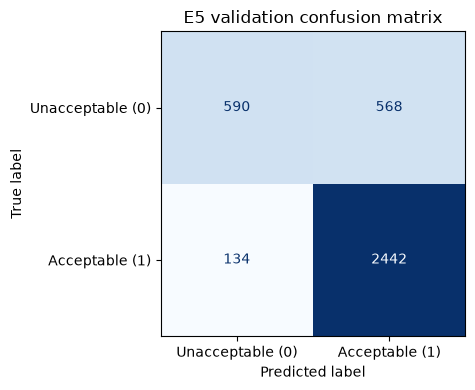

In [ ]:
# G1 — Category-wise validation performance and confusion matrix
val_pred = (val_prob1 >= SELECTED_THRESHOLD).astype(int)
val_analysis = val_df[["sentence", "label", "category", "source", "source_group"]].copy().reset_index(drop=True)
val_analysis["prob_acceptable"] = val_prob1
val_analysis["prediction"] = val_pred
val_analysis["correct"] = (val_analysis["prediction"] == val_analysis["label"])
val_analysis.to_csv(FINAL_OUT / "e5_validation_predictions.csv", index=False)

category_results = []
for category, frame in val_analysis.groupby("category", sort=True):
    vals = evaluate(frame["label"], frame["prediction"])
    cm = confusion_matrix(frame["label"], frame["prediction"], labels=[0, 1])
    category_results.append({
        "category": category, "samples": len(frame),
        "label0_count": int((frame["label"] == 0).sum()),
        "label1_count": int((frame["label"] == 1).sum()),
        "label0_recall": float(cm[0, 0] / cm[0].sum()) if cm[0].sum() else float("nan"),
        "label1_recall": float(cm[1, 1] / cm[1].sum()) if cm[1].sum() else float("nan"),
        **vals
    })
category_val = pd.DataFrame(category_results).sort_values("samples", ascending=False)
category_val.to_csv(FINAL_OUT / "e5_validation_category_metrics.csv", index=False)
display(category_val.round(4))

cm_val = confusion_matrix(y_val, val_pred, labels=[0, 1])
print("E5 validation confusion matrix (true label rows; predicted columns):")
print(cm_val)
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(
    confusion_matrix=cm_val, display_labels=["Unacceptable (0)", "Acceptable (1)"]
).plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
ax.set_title("E5 validation confusion matrix")
fig.tight_layout()
fig.savefig(FINAL_OUT / "e5_validation_confusion_matrix.png", dpi=180)
plt.show()

In [ ]:
# G2 — Confident mistakes on validation (not test)
errors = val_analysis.loc[~val_analysis["correct"]].copy()
errors["predicted_confidence"] = np.where(
    errors["prediction"].eq(1), errors["prob_acceptable"],
    1.0 - errors["prob_acceptable"]
)
print("Validation mistakes:", len(errors), "out of", len(val_analysis))
print("\nFalse positives: predicted acceptable, gold unacceptable")
display(errors.loc[(errors["label"] == 0) & (errors["prediction"] == 1)]
        .sort_values("predicted_confidence", ascending=False)
        [["sentence", "category", "label", "prediction",
          "prob_acceptable", "source"]].head(12))
print("\nFalse negatives: predicted unacceptable, gold acceptable")
display(errors.loc[(errors["label"] == 1) & (errors["prediction"] == 0)]
        .sort_values("predicted_confidence", ascending=False)
        [["sentence", "category", "label", "prediction",
          "prob_acceptable", "source"]].head(12))

errors.to_csv(FINAL_OUT / "e5_validation_errors.csv", index=False)
print("Report note: these are corpus-label disagreements; investigate them manually "
      "before attributing the cause to morphology or anglicisms.")

Validation mistakes: 702 out of 3734

False positives: predicted acceptable, gold unacceptable


,sentence,category,label,prediction,prob_acceptable,source
1875,Elle a été ma voisine pendant plusieurs années...,morphology,0,1,0.964996,https://vitrinelinguistique.oqlf.gouv.qc.ca/22...
3106,"Bon matin, Monsieur.",anglicism,0,1,0.964641,https://vitrinelinguistique.oqlf.gouv.qc.ca/22...
3192,Il était dix heures environs lorsque Justin ar...,semantic,0,1,0.964297,https://vitrinelinguistique.oqlf.gouv.qc.ca/24...
675,Clovis a étudié à l’école Joseph François Perr...,syntax,0,1,0.964132,https://vitrinelinguistique.oqlf.gouv.qc.ca/23...
586,"Ne t’inquiète pas, tout est sous contrôle.",anglicism,0,1,0.964111,https://vitrinelinguistique.oqlf.gouv.qc.ca/22...
707,Clovis a étudié à l’école Joseph François-Perr...,syntax,0,1,0.963986,https://vitrinelinguistique.oqlf.gouv.qc.ca/23...
1062,Roselyne était vigilante et tenait bonne.,morphology,0,1,0.963918,https://vitrinelinguistique.oqlf.gouv.qc.ca/21...
2918,La soupe sentait bonne.,morphology,0,1,0.963837,https://vitrinelinguistique.oqlf.gouv.qc.ca/21...
1803,"Je suis passé au bureau hier soir, mais il y a...",syntax,0,1,0.963719,https://vitrinelinguistique.oqlf.gouv.qc.ca/22...
2261,"À cette idée, la majorité des jeunes adhèrent.",morphology,0,1,0.963707,https://vitrinelinguistique.oqlf.gouv.qc.ca/24...



False negatives: predicted unacceptable, gold acceptable


,sentence,category,label,prediction,prob_acceptable,source
790,"Il s’était levé frais et dispos, et avait appe...",syntax,1,0,0.017615,https://vitrinelinguistique.oqlf.gouv.qc.ca/23...
2320,Il s’était levé frais et dispos et avait appel...,syntax,1,0,0.017672,https://vitrinelinguistique.oqlf.gouv.qc.ca/23...
2304,Nous sommes fière de publier les résultats de ...,morphology,1,0,0.017681,https://vitrinelinguistique.oqlf.gouv.qc.ca/21...
505,La pluie tombait serré.,morphology,1,0,0.018024,https://vitrinelinguistique.oqlf.gouv.qc.ca/24...
1820,"Nous, Maurice Lemay, expert agréé, avons été r...",morphology,1,0,0.018154,https://vitrinelinguistique.oqlf.gouv.qc.ca/21...
1496,"Pour dessiner, tu devrais utiliser des crayons...",morphology,1,0,0.018289,https://vitrinelinguistique.oqlf.gouv.qc.ca/24...
401,Les entreprises optent de plus en plus pour de...,morphology,1,0,0.018306,https://vitrinelinguistique.oqlf.gouv.qc.ca/23...
1895,La ministre a discouru sur la gestion du patri...,anglicism,1,0,0.019210,https://vitrinelinguistique.oqlf.gouv.qc.ca/21...
1878,L’humidité a augmenté ce soir en raison du ser...,morphology,1,0,0.019867,https://vitrinelinguistique.oqlf.gouv.qc.ca/22...
888,Ces candidates se sont montrées bons princes e...,morphology,1,0,0.020202,https://vitrinelinguistique.oqlf.gouv.qc.ca/21...


Report note: these are corpus-label disagreements; investigate them manually before attributing the cause to morphology or anglicisms.


## Part H — Locked QFrCoLA test evaluation (explicit opt-in)

**Do not enable this until Parts E–G are complete and you have settled the model checkpoint and threshold using only validation.**

Set `RUN_FINAL_TEST = True` in the next cell when you are ready. It will produce and save QFrCoLA test metrics. If a test-result JSON already exists, the cell will **not run the test again**, even if re-executed. To evaluate a fundamentally different finalized protocol, document the change and use a new, truly independent holdout instead of repeatedly probing QFrCoLA test.

**Interpretation warning:** Earlier Progress experiments already reported QFrCoLA test results, so this is source-disjoint evaluation but not wholly new, untouched evidence for the project.

In [18]:
print("Selected seed:", BEST_SEED)
print("Selected threshold:", SELECTED_THRESHOLD)
print("Checkpoint:", BEST_CHECKPOINT)

Selected seed: 360
Selected threshold: 0.8
Checkpoint: qfrcola_final_results\e5_seed_360\best_model


In [ ]:
# H1 — Change to True ONLY after final validation model/threshold selection
RUN_FINAL_TEST = True
TEST_RESULT_PATH = FINAL_OUT / "e5_locked_qfrcola_test.json"

if not RUN_FINAL_TEST:
    print("Test evaluation SKIPPED by design. Set RUN_FINAL_TEST=True once "
          "after finalizing E5 on validation.")
elif TEST_RESULT_PATH.exists():
    print("Previously locked test report detected; NOT reevaluating test:", TEST_RESULT_PATH)
    with open(TEST_RESULT_PATH, "r", encoding="utf-8") as f:
        locked_test = json.load(f)
    print(json.dumps(locked_test, indent=2, ensure_ascii=False))
else:
    # Freeze and record choices BEFORE reading test predictions.
    assert (FINAL_OUT / "selection.json").exists(), "Run Part F first."
    with open(FINAL_OUT / "selection.json", encoding="utf-8") as f:
        frozen = json.load(f)
    assert int(frozen["seed"]) == BEST_SEED
    assert float(frozen["threshold"]) == SELECTED_THRESHOLD

    test_tokenized = tokenize_frame(test_df)
    test_loader = make_loader(test_tokenized, EVAL_BATCH_SIZE, shuffle=False)
    y_test, test_prob1, test_loss = predict_loader(
        best_model, test_loader, desc="LOCKED test evaluation"
    )
    assert np.array_equal(y_test, test_df["label"].to_numpy(dtype=int))
    y_test_pred = (test_prob1 >= SELECTED_THRESHOLD).astype(int)
    locked_test = {
        "model": MODEL_NAME, "seed": BEST_SEED,
        "checkpoint": str(BEST_CHECKPOINT),
        "threshold_frozen_on_validation": SELECTED_THRESHOLD,
        "test_samples": int(len(y_test)),
        "test_loss": float(test_loss),
        "metrics": evaluate(y_test, y_test_pred),
        "test_confusion_matrix_labels_0_1": confusion_matrix(
            y_test, y_test_pred, labels=[0, 1]
        ).tolist(),
        "caveat": "QFrCoLA test had been inspected in the Progress project; not a wholly untouched holdout"
    }
    with open(TEST_RESULT_PATH, "w", encoding="utf-8") as f:
        json.dump(locked_test, f, indent=2, ensure_ascii=False)
    display(pd.DataFrame([locked_test["metrics"]]).round(4))
    print("Locked test results SAVED:", TEST_RESULT_PATH)

    test_records = test_df[["sentence", "label", "category", "source"]].copy().reset_index(drop=True)
    test_records["predicted"] = y_test_pred
    test_records["prob_acceptable"] = test_prob1
    test_records.to_csv(FINAL_OUT / "e5_locked_test_predictions.csv", index=False)
    cat_test = []
    for category, group in test_records.groupby("category"):
        cat_test.append({"category": category, "samples": len(group),
                         **evaluate(group["label"], group["predicted"])})
    pd.DataFrame(cat_test).to_csv(
        FINAL_OUT / "e5_locked_test_category_metrics.csv", index=False
    )
    print("Test by category (saved):")
    display(pd.DataFrame(cat_test).sort_values("samples", ascending=False).round(4))

CamemBERT subword tokenization: 100%|██████████| 3839/3839 [00:00<00:00, 41656.68 examples/s]


,accuracy,macro_f1,mcc,f1_unacceptable,f1_acceptable
0,0.8307,0.774,0.5765,0.6608,0.8872


Locked test results SAVED: qfrcola_final_results\e5_locked_qfrcola_test.json
Test by category (saved):


,category,samples,accuracy,macro_f1,mcc,f1_unacceptable,f1_acceptable
1,morphology,1616,0.8069,0.7626,0.5428,0.6601,0.8652
2,semantic,936,0.8440,0.7752,0.5881,0.6507,0.8996
3,syntax,745,0.9248,0.8609,0.7308,0.7667,0.9552
0,anglicism,542,0.7491,0.7086,0.5170,0.6000,0.8172


## Part I — Independent external evaluation (optional; genuine new samples only)

Prepare a UTF-8 CSV at `qfrcola_final_results/external_labeled.csv` with **`sentence,label,source`** columns (optional `category`). Each label must be **manually assigned according to a documented protocol** (0 = unacceptable; 1 = acceptable). Source should be the original page URL or unique provenance ID; don't recycle URLs or sentences from QFrCoLA. Do **not** use these sentences for model/threshold selection.

Set `RUN_EXTERNAL_EVAL=True` in Part I only after annotation is final. If no external CSV is present, the cell reports `SKIPPED` instead of inventing data or results. The code checks exact URL and normalized-text overlap with the complete QFrCoLA corpus. This does not, by itself, prove independent authorship or absence of paraphrases.

In [9]:
# Part I0 — External dataset independence audit
# No model loading, training, or prediction.

import re
import unicodedata
import pandas as pd
from pathlib import Path
from urllib.parse import urldefrag

candidate_path = Path(
    "qfrcola_final_results/"
    "QFrCoLA_PartI_External_Labeled_AUTHOR_CONFIRM_FIRST.csv"
)

assert candidate_path.exists(), f"File not found: {candidate_path}"

external = pd.read_csv(candidate_path, encoding="utf-8-sig")

required = {"sentence", "label", "source"}
assert required.issubset(external.columns)
assert not external[list(required)].isna().any().any()
assert set(external["label"].unique()) == {0, 1}

# Assemble the COMPLETE original QFrCoLA dataset
original = pd.concat([
    train_df.assign(split="train"),
    val_df.assign(split="validation"),
    test_df.assign(split="test")
], ignore_index=True)

assert len(original) == 25153, (
    f"Expected 25153 original rows, got {len(original)}"
)
assert len(external) == 80

# Match original cleaning rules
def exact_key(s):
    return unicodedata.normalize(
        "NFC", str(s)
    ).strip()

    # Strict original comparison

# More conservative matching:
# ignore capitalization, whitespace and apostrophe style
def relaxed_key(s):
    s = unicodedata.normalize("NFC", str(s))
    s = s.replace("’", "'").replace("ʼ", "'")
    s = re.sub(r"\s+", " ", s)
    return s.strip().casefold()

def url_key(s):
    return urldefrag(str(s).strip())[0].rstrip("/").lower()

external["_exact"] = external["sentence"].map(exact_key)
external["_relaxed"] = external["sentence"].map(relaxed_key)

original["_exact"] = original["sentence"].map(exact_key)
original["_relaxed"] = original["sentence"].map(relaxed_key)

# 1. Duplicates inside the external set
internal_duplicates = external["_relaxed"].duplicated().sum()

# 2. Exact / relaxed text overlap by split
print("EXTERNAL DATASET INDEPENDENCE CHECK")
print("=" * 48)
print("External samples:", len(external))
print("Original QFrCoLA samples:", len(original))
print("Internal duplicates:", internal_duplicates)

total_exact = 0
total_relaxed = 0

for split in ["train", "validation", "test"]:
    reference = original[original["split"] == split]

    exact_matches = external["_exact"].isin(
        set(reference["_exact"])
    )
    relaxed_matches = external["_relaxed"].isin(
        set(reference["_relaxed"])
    )

    n_exact = int(exact_matches.sum())
    n_relaxed = int(relaxed_matches.sum())

    total_exact += n_exact
    total_relaxed += n_relaxed

    print(
        f"{split:12s}: "
        f"exact={n_exact}, relaxed={n_relaxed}"
    )

# 3. External source identifiers
original_urls = set(original["source"].map(url_key))
source_overlap = external["source"].map(
    url_key
).isin(original_urls)

print("\nExternal source-ID overlap:",
      int(source_overlap.sum()))

# 4. Check whether the OQLF RULE PAGES
# themselves also appear among QFrCoLA sources
rule_overlap = pd.Series(False, index=external.index)

if "rule_url" in external.columns:
    rule_overlap = external["rule_url"].map(
        url_key
    ).isin(original_urls)

    print("OQLF rule-page URL overlap:",
          int(rule_overlap.sum()))

# 5. Final audit
print("\n" + "=" * 48)

passed = (
    internal_duplicates == 0
    and total_exact == 0
    and total_relaxed == 0
    and not source_overlap.any()
)

if passed:
    print("PASS: No exact or relaxed text overlap.")
    print("PASS: No overlapping external source IDs.")
else:
    print("WARNING: Overlap found. Review before Part I.")

    flagged = external[
        external["_relaxed"].isin(
            set(original["_relaxed"])
        ) | source_overlap
    ]

    display(flagged[["sentence", "label", "source"]])

if rule_overlap.any():
    print(
        "\nCAUTION: Some OQLF rule pages may already "
        "be represented in QFrCoLA. This does not "
        "necessarily mean the NEWLY WRITTEN sentences "
        "are duplicated, but it must be documented."
    )
    display(
        external.loc[rule_overlap, ["sentence", "rule_url"]]
        .drop_duplicates("rule_url")
        .head(20)
    )

print("\nAudit finished. No model was evaluated.")

EXTERNAL DATASET INDEPENDENCE CHECK
External samples: 80
Original QFrCoLA samples: 25153
Internal duplicates: 0
train       : exact=0, relaxed=0
validation  : exact=0, relaxed=0
test        : exact=0, relaxed=0

External source-ID overlap: 0
OQLF rule-page URL overlap: 0

PASS: No exact or relaxed text overlap.
PASS: No overlapping external source IDs.

Audit finished. No model was evaluated.


In [10]:
# Part I0b — Lock the external test dataset
# No model inference or training.

from pathlib import Path
import shutil
import hashlib
import pandas as pd

FINAL_OUT = Path("qfrcola_final_results")

source_file = FINAL_OUT / (
    "QFrCoLA_PartI_External_Labeled_AUTHOR_CONFIRM_FIRST.csv"
)
locked_file = FINAL_OUT / "external_labeled.csv"

assert source_file.exists(), "Candidate CSV not found."

if locked_file.exists():
    assert locked_file.read_bytes() == source_file.read_bytes(), (
        "external_labeled.csv already exists with different content."
    )
    print("Existing locked file matches the reviewed CSV.")
else:
    shutil.copy2(source_file, locked_file)

locked = pd.read_csv(locked_file, encoding="utf-8-sig")

assert len(locked) == 80
assert locked["label"].value_counts().to_dict() == {
    0: 40, 1: 40
}
assert locked["pair_id"].nunique() == 40

digest = hashlib.sha256(locked_file.read_bytes()).hexdigest()

print("External dataset locked:", locked_file.resolve())
print("Samples:", len(locked))
print("Label counts:", locked["label"].value_counts().to_dict())
print("SHA256:", digest)
print("Ready for independent evaluation.")

External dataset locked: C:\Users\<local-user>\qfrcola_final_results\external_labeled.csv
Samples: 80
Label counts: {1: 40, 0: 40}
SHA256: 7e3e8d705005fb484bcd6e84a91dcd183c5c491fc55f468e300919ee2901443d
Ready for independent evaluation.


In [19]:
# I1 — Evaluate genuinely new manually labeled samples, if a CSV was supplied
EXTERNAL_CSV = FINAL_OUT / "external_labeled.csv"
EXTERNAL_RESULTS = FINAL_OUT / "e5_external_evaluation.json"
RUN_EXTERNAL_EVAL = True  # Explicit opt-in after external annotation is finalized

if not RUN_EXTERNAL_EVAL:
    print("Independent external evaluation SKIPPED (RUN_EXTERNAL_EVAL=False).")
elif not EXTERNAL_CSV.exists():
    print("Independent evaluation SKIPPED: no external_labeled.csv yet.")
    print("Required columns: sentence,label,source; optional: category.")
elif EXTERNAL_RESULTS.exists():
    print("Independent evaluation already saved; not recomputing:", EXTERNAL_RESULTS)
    with open(EXTERNAL_RESULTS, encoding="utf-8") as f:
        print(json.dumps(json.load(f), indent=2, ensure_ascii=False))
else:
    external = pd.read_csv(EXTERNAL_CSV, encoding="utf-8-sig")
    expected = {"sentence", "label", "source"}
    assert expected.issubset(external.columns), f"Missing: {expected - set(external.columns)}"
    assert not external[["sentence", "label", "source"]].isna().any().any()
    external["sentence"] = external["sentence"].map(normalize_sentence)
    external["source"] = external["source"].astype(str).str.strip()
    external["label"] = pd.to_numeric(external["label"], errors="coerce")
    assert len(external) > 0 and set(external["label"].dropna().unique()) <= {0, 1}
    assert external["label"].notna().all(), "External labels must be 0 or 1."
    assert external["sentence"].str.len().gt(0).all()
    assert external["source"].str.len().gt(0).all()
    assert external["sentence"].is_unique, "Remove duplicate external sentences."

    common_text = set(external["sentence"]) & set(df["sentence"])
    common_urls = set(external["source"]) & set(df_raw["source"].astype(str))
    assert not common_text, f"External sentences overlap QFrCoLA: {len(common_text)}"
    assert not common_urls, f"External sources overlap QFrCoLA: {len(common_urls)}"
    external["label"] = external["label"].astype(int)

    ext_tokenized = tokenize_frame(external)
    ext_loader = make_loader(ext_tokenized, EVAL_BATCH_SIZE)
    y_ext, ext_prob1, ext_loss = predict_loader(
        best_model, ext_loader, desc="Independent external evaluation"
    )
    ext_pred = (ext_prob1 >= SELECTED_THRESHOLD).astype(int)
    ext_metrics = evaluate(y_ext, ext_pred)
    ext_report = {
        "samples": int(len(external)), "model": MODEL_NAME,
        "checkpoint_seed": BEST_SEED,
        "validation_selected_threshold": SELECTED_THRESHOLD,
        "cross_entropy": float(ext_loss),
        "metrics": ext_metrics,
        "confusion_matrix": confusion_matrix(y_ext, ext_pred, labels=[0, 1]).tolist(),
        "overlap_check": "no exact normalized text or source IDs in QFrCoLA",
        "annotation": "must be manually documented by project author",
    }
    with open(EXTERNAL_RESULTS, "w", encoding="utf-8") as f:
        json.dump(ext_report, f, indent=2, ensure_ascii=False)
    external["prediction"] = ext_pred
    external["prob_acceptable"] = ext_prob1
    external.to_csv(FINAL_OUT / "e5_external_predictions.csv", index=False)
    print("Independent evaluation complete:")
    display(pd.DataFrame([ext_metrics]).round(4))
    print("Saved:", EXTERNAL_RESULTS)

CamemBERT subword tokenization: 100%|██████████| 80/80 [00:00<00:00, 9980.50 examples/s]
                                                                              

Independent evaluation complete:


,accuracy,macro_f1,mcc,f1_unacceptable,f1_acceptable
0,0.6375,0.5827,0.3993,0.4314,0.7339


Saved: qfrcola_final_results\e5_external_evaluation.json


## Part J — Save reproducibility manifest & report checklist

All files are stored under `qfrcola_final_results/`. Data preprocessing files from the original Part C remain in `qfrcola_results/`.

**For the final report:** explain the 2,798 source-group split; compare archived E1–E4 validation results and new E5 validation results; distinguish threshold tuning from training; report all final test numbers with the prior-exposure caveat; include negative-class recall and anglicism subgroup; report independent test only when labels actually exist. The Final Report rubric may change the final presentation structure.

**Do not commit** large pretrained checkpoints, Hugging Face caches, or any confidential files. Upload the Notebook (and selected small result tables) after checking that its outputs contain no sensitive local paths or identifiers.

In [21]:
# Part J — Restore result paths independently
# No training or inference required

from pathlib import Path

FINAL_OUT = Path("qfrcola_final_results")

TEST_RESULT_PATH = FINAL_OUT / "e5_locked_qfrcola_test.json"
EXTERNAL_RESULTS = FINAL_OUT / "e5_external_evaluation.json"

print("QFrCoLA test result found:", TEST_RESULT_PATH.exists())
print("External evaluation result found:", EXTERNAL_RESULTS.exists())

assert TEST_RESULT_PATH.exists(), "Saved QFrCoLA test result missing."
assert EXTERNAL_RESULTS.exists(), "Saved external test result missing."

QFrCoLA test result found: True
External evaluation result found: True


In [22]:
# J1 — Save environment, split, and training configuration to disk

EXTERNAL_RESULTS = FINAL_OUT / "e5_external_evaluation.json"

import platform
import importlib.metadata as metadata

manifest = {
    "project": "APS360_QFrCoLA_Final",
    "dataset": "graalul/qfrcola",
    "model": MODEL_NAME,
    "python": sys.version.split()[0],
    "platform": platform.platform(),
    "torch": torch.__version__,
    "datasets": datasets.__version__,
    "transformers": transformers.__version__,
    "huggingface_hub": huggingface_hub.__version__,
    "pandas": pd.__version__,
    "sklearn": metadata.version("scikit-learn"),
    "device": str(DEVICE),
    "gpu": torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else None,
    "split_search_seed": SEED,
    "chosen_split_seed": int(chosen_seed),
    "dataset_split_sha256": DATA_FINGERPRINT,
    "split_sizes": {"train": len(train_df), "validation": len(val_df),
                    "test": len(test_df)},
    "source_groups": int(df["source_group"].nunique()),
    "max_subwords": MAX_SUBWORDS,
    "training_seeds": TRAINING_SEEDS,
    "selected_seed": BEST_SEED,
    "selected_validation_threshold": SELECTED_THRESHOLD,
    "training_hyperparameters": {
        "batch_size": TRAIN_BATCH_SIZE,
        "eval_batch_size": EVAL_BATCH_SIZE,
        "accumulation": GRAD_ACCUM_STEPS,
        "epochs_max": EPOCHS,
        "learning_rate": LEARNING_RATE,
        "weight_decay": WEIGHT_DECAY,
        "warmup_ratio": WARMUP_RATIO,
        "early_stop_patience": EARLY_STOP_PATIENCE,
    },
    "test_evaluated": bool(TEST_RESULT_PATH.exists()),
    "external_evaluated": bool(EXTERNAL_RESULTS.exists()),
}
with open(FINAL_OUT / "reproducibility_manifest.json", "w", encoding="utf-8") as f:
    json.dump(manifest, f, indent=2, ensure_ascii=False)
print("Reproducibility manifest saved:", FINAL_OUT / "reproducibility_manifest.json")
print("Results available:")
for p in sorted(FINAL_OUT.iterdir()):
    print(" ", p.name)

Reproducibility manifest saved: qfrcola_final_results\reproducibility_manifest.json
Results available:
  e5_external_evaluation.json
  e5_external_predictions.csv
  e5_locked_qfrcola_test.json
  e5_locked_test_category_metrics.csv
  e5_locked_test_predictions.csv
  e5_seed_360
  e5_seed_361
  e5_seed_362
  e5_training_curves.png
  e5_validation_category_metrics.csv
  e5_validation_confusion_matrix.png
  e5_validation_errors.csv
  e5_validation_predictions.csv
  e5_validation_runs.csv
  external_labeled.csv
  QFrCoLA_PartI_External_Labeled_AUTHOR_CONFIRM_FIRST.csv
  reproducibility_manifest.json
  selected_validation_predictions.npz
  selection.json
  validation_model_comparison.csv
  validation_threshold_macro_f1.png
  validation_threshold_search.csv


##Part K  
Export lightweight results for review

In [23]:
# Excludes all CamemBERT model weights.

from pathlib import Path
from zipfile import ZipFile, ZIP_DEFLATED

result_dir = Path("qfrcola_final_results")
zip_path = result_dir.parent / "QFrCoLA_Results_Lightweight.zip"

assert result_dir.is_dir(), "Results folder not found."

# Include all root-level reports and plots
allowed_extensions = {".json", ".csv", ".png", ".npz"}

files = [
    p for p in result_dir.iterdir()
    if p.is_file() and p.suffix.lower() in allowed_extensions
]

# Include training summaries and histories for all seeds
for seed_dir in sorted(result_dir.glob("e5_seed_*")):
    for filename in ["run_summary.json", "training_history.csv"]:
        p = seed_dir / filename
        if p.is_file():
            files.append(p)

# Compress without modifying original files
with ZipFile(zip_path, "w", ZIP_DEFLATED, compresslevel=6) as zf:
    for p in sorted(files):
        zf.write(p, arcname=p.relative_to(result_dir))

print("Created:", zip_path.resolve())
print("Files included:", len(files))
print("ZIP size: {:.2f} MB".format(
    zip_path.stat().st_size / (1024 ** 2)
))
print("\nOriginal checkpoints remain untouched.")

Created: C:\Users\<local-user>\QFrCoLA_Results_Lightweight.zip
Files included: 25
ZIP size: 0.62 MB

Original checkpoints remain untouched.
